<a href="https://colab.research.google.com/github/rohinerd/flood_warnings_classifier/blob/main/flood_warnings_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Install libraries

In [1]:
!pip install odfpy -q


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


### List contents

In [2]:
!ls -la

total 3560
drwxr-xr-x 1 root root    4096 Nov  5 21:29 .
drwxr-xr-x 1 root root    4096 Nov  5 20:52 ..
drwxr-xr-x 4 root root    4096 Nov  4 16:00 .config
-rw-r--r-- 1 root root 3628573 Nov  5 21:29 Historic_Flood_Warnings.zip
drwxr-xr-x 1 root root    4096 Oct 26 22:18 sample_data


## 2. Unzip the flood warnings data

In [3]:
!unzip -o Historic_Flood_Warnings.zip -d flood_data
!ls -lh flood_data

Archive:  Historic_Flood_Warnings.zip
  inflating: flood_data/202607 Historic Flood Warnings Documentation.odt  
  inflating: flood_data/202607 Historic Flood Warnings – EA Only.ods  
total 3.6M
-rw-rw-rw- 1 root root 270K Jul  2 07:39 '202607 Historic Flood Warnings Documentation.odt'
-rw-rw-rw- 1 root root 3.4M Jul  2 08:13 '202607 Historic Flood Warnings – EA Only.ods'


## 3. List the sheets in the EA-only spreadsheet

In [4]:
import glob
import pandas as pd

ods_path = glob.glob("flood_data/*.ods")[0]
sheets = pd.read_excel(ods_path, engine="odf", sheet_name=None)

for name, sheet in sheets.items():
    print(name, sheet.shape)

tblAllData (85993, 5)


## 4. Inspect the column headers and first rows

In [5]:
df = sheets["tblAllData"]

print(df.columns.tolist())
print(df.head())
print(df.dtypes)

['DATE', 'AREA', 'CODE', 'WARNING / ALERT AREA NAME', 'TYPE']
                 DATE               AREA        CODE  \
0 2006-01-31 13:55:34         SW - Devon   113WACT2a   
1 2006-01-31 16:33:10  SW - North Wessex  112WACTAVN   
2 2006-02-08 11:19:45      ANG - Eastern   054WATBT1   
3 2006-02-08 11:25:26      ANG - Eastern   054WATBT2   
4 2006-02-08 11:32:20      ANG - Eastern   054WATBT3   

           WARNING / ALERT AREA NAME         TYPE  
0                Devon Coast (North)  Flood Watch  
1               Porlock to Avonmouth  Flood Watch  
2  Tidal Rivers Bure, Ant and Thurne  Flood Watch  
3                   Tidal River Yare  Flood Watch  
4                Tidal River Waveney  Flood Watch  
DATE                         datetime64[ns]
AREA                                 object
CODE                                 object
WARNING / ALERT AREA NAME            object
TYPE                                 object
dtype: object


## 5. Check the values in the TYPE column

In [6]:
print(df["TYPE"].value_counts())
print(df["DATE"].min(), df["DATE"].max())

TYPE
Flood Alert                    43325
Flood Warning                  19597
Flood Watch                    11032
Update Flood Alert              5535
Flood alert                     3011
Update Flood Warning            2071
Flood warning                    923
Severe Flood Warning             485
Update Severe Flood Warning       11
Severe flood warning               3
Name: count, dtype: int64
2006-01-31 13:55:34 2026-06-25 17:45:57


## 6. Clean the TYPE labels and define the target

In [7]:
df["TYPE_CLEAN"] = df["TYPE"].str.strip().str.lower()
df = df[~df["TYPE_CLEAN"].str.startswith("update")]
df = df[df["TYPE_CLEAN"].isin(["flood alert", "flood warning", "severe flood warning"])]
df["SEVERE"] = (df["TYPE_CLEAN"] == "severe flood warning").astype(int)

print(df["SEVERE"].value_counts())
print(df["TYPE_CLEAN"].value_counts())

SEVERE
0    66856
1      488
Name: count, dtype: int64
TYPE_CLEAN
flood alert             46336
flood warning           20520
severe flood warning      488
Name: count, dtype: int64


## 7. Split by time into training and test years

Cut-off at 2019: training uses 2006 to 2019 and testing uses 2020 onwards. This gives 57 severe warnings in the test years, the most of any cut-off tested.

In [8]:
for cutoff in [2019, 2020, 2021, 2022]:
    train = df[df["DATE"].dt.year <= cutoff]
    test = df[df["DATE"].dt.year > cutoff]
    print(f"cutoff {cutoff}: train={len(train)} severe={train['SEVERE'].sum()} | test={len(test)} severe={test['SEVERE'].sum()}")

cutoff 2019: train=36087 severe=431 | test=31257 severe=57
cutoff 2020: train=41537 severe=453 | test=25807 severe=35
cutoff 2021: train=45032 severe=460 | test=22312 severe=28
cutoff 2022: train=47744 severe=474 | test=19600 severe=14


In [10]:
CUTOFF = 2019
train = df[df["DATE"].dt.year <= CUTOFF]
test = df[df["DATE"].dt.year > CUTOFF]

## 8. Baseline: always predict not severe

In [11]:
from sklearn.metrics import f1_score, accuracy_score

y_test = test["SEVERE"]
baseline_pred = [0] * len(y_test)

print("accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("severe F1:", f1_score(y_test, baseline_pred, zero_division=0))

accuracy: 0.9982
severe F1: 0.0


## 9. Train a classifier on area and month

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

def add_features(d):
    d = d.copy()
    d["MONTH"] = d["DATE"].dt.month.astype(str)
    return d

train_f = add_features(train)
test_f = add_features(test)

pipe = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["AREA", "MONTH"])]),
    LogisticRegression(class_weight="balanced", max_iter=1000),
)
pipe.fit(train_f[["AREA", "MONTH"]], train_f["SEVERE"])
pred = pipe.predict(test_f[["AREA", "MONTH"]])

print("accuracy:", round(accuracy_score(test_f["SEVERE"], pred), 4))
print("severe F1:", round(f1_score(test_f["SEVERE"], pred), 4))

accuracy: 0.9655
severe F1: 0.0


## 9a. Check what the classifier predicts

In [13]:
import numpy as np

print("predicted severe:", pred.sum())
print("actual severe:", test_f["SEVERE"].sum())
print("true positives:", np.sum((pred == 1) & (test_f["SEVERE"] == 1)))

probs = pipe.predict_proba(test_f[["AREA", "MONTH"]])[:, 1]
print("max probability:", probs.max().round(3))
print("mean probability for actual severe:", probs[test_f["SEVERE"].values == 1].mean().round(3))

predicted severe: 1020
actual severe: 57
true positives: 0
max probability: 0.864
mean probability for actual severe: 0.065


## 9b. Add an area history feature and measure ranking with AUC

In [14]:
from sklearn.metrics import roc_auc_score

overall_rate = train_f["SEVERE"].mean()
stats = train_f.groupby("AREA")["SEVERE"].agg(["sum", "count"])
stats["area_rate"] = (stats["sum"] + 5 * overall_rate) / (stats["count"] + 5)

train_f["AREA_RATE"] = train_f["AREA"].map(stats["area_rate"]).fillna(overall_rate)
test_f["AREA_RATE"] = test_f["AREA"].map(stats["area_rate"]).fillna(overall_rate)

model = LogisticRegression(class_weight="balanced", max_iter=1000)
model.fit(train_f[["AREA_RATE"]], train_f["SEVERE"])
probs = model.predict_proba(test_f[["AREA_RATE"]])[:, 1]
pred = (probs >= 0.5).astype(int)

print("AUC:", round(roc_auc_score(test_f["SEVERE"], probs), 3))
print("severe F1:", round(f1_score(test_f["SEVERE"], pred), 3))

AUC: 0.451
severe F1: 0.0


## 9c. Add a weekly warning-frequency feature and re-measure

In [16]:
df_sorted = df.sort_values("DATE").copy()
df_sorted["WEEK"] = df_sorted["DATE"].dt.to_period("W").dt.start_time

weekly_counts = df_sorted.groupby("WEEK").size()
weekly_counts = weekly_counts.reindex(pd.date_range(weekly_counts.index.min(), weekly_counts.index.max(), freq="W-MON"), fill_value=0)

# Use the previous week's count, so the feature never includes the current week
prev_week_count = weekly_counts.shift(1).fillna(0)
df_sorted["PREV_WEEK_COUNT"] = df_sorted["WEEK"].map(prev_week_count).fillna(0)

train_w = df_sorted[df_sorted["DATE"].dt.year <= CUTOFF]
test_w = df_sorted[df_sorted["DATE"].dt.year > CUTOFF]

model_w = LogisticRegression(class_weight="balanced", max_iter=1000)
model_w.fit(train_w[["PREV_WEEK_COUNT"]], train_w["SEVERE"])
probs_w = model_w.predict_proba(test_w[["PREV_WEEK_COUNT"]])[:, 1]
pred_w = (probs_w >= 0.5).astype(int)

print("AUC:", round(roc_auc_score(test_w["SEVERE"], probs_w), 3))
print("severe F1:", round(f1_score(test_w["SEVERE"], pred_w), 3))

AUC: 0.334
severe F1: 0.002


## 9d. Plot the ROC curve for the current classifier

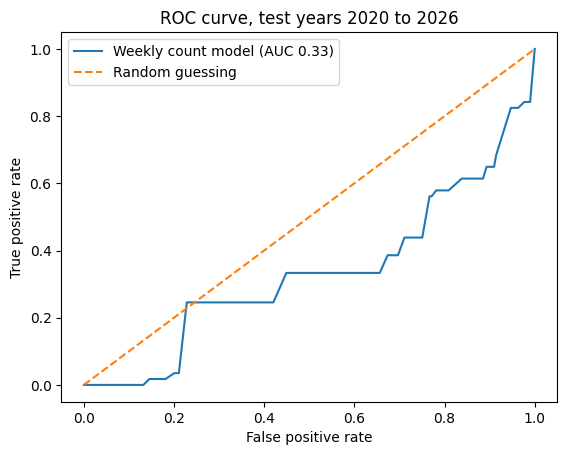

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, _ = roc_curve(test_w["SEVERE"], probs_w)
auc = roc_auc_score(test_w["SEVERE"], probs_w)

fig, ax = plt.subplots()
ax.plot(fpr, tpr, label=f"Weekly count model (AUC {auc:.2f})")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random guessing")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curve, test years 2020 to 2026")
ax.legend()

fig.savefig("roc_weekly_count.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Compare cut-off years side by side

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
import pandas as pd

def run_weekly_count(cutoff):
    d = df.sort_values("DATE").copy()
    d["WEEK"] = d["DATE"].dt.to_period("W").dt.start_time
    weekly = d.groupby("WEEK").size()
    weekly = weekly.reindex(pd.date_range(weekly.index.min(), weekly.index.max(), freq="W-MON"), fill_value=0)
    d["PREV_WEEK_COUNT"] = d["WEEK"].map(weekly.shift(1).fillna(0)).fillna(0)

    tr = d[d["DATE"].dt.year <= cutoff]
    te = d[d["DATE"].dt.year > cutoff]
    m = LogisticRegression(class_weight="balanced", max_iter=1000)
    m.fit(tr[["PREV_WEEK_COUNT"]], tr["SEVERE"])
    p = m.predict_proba(te[["PREV_WEEK_COUNT"]])[:, 1]
    pred = (p >= 0.5).astype(int)
    return {
        "cutoff": cutoff,
        "train_severe": int(tr["SEVERE"].sum()),
        "test_severe": int(te["SEVERE"].sum()),
        "AUC": round(roc_auc_score(te["SEVERE"], p), 3),
        "severe_F1": round(f1_score(te["SEVERE"], pred, zero_division=0), 3),
    }

results = pd.DataFrame([run_weekly_count(c) for c in [2015, 2016, 2017, 2018, 2019, 2020, 2021]])
print(results.to_string(index=False))

 cutoff  train_severe  test_severe   AUC  severe_F1
   2015           396           92 0.446      0.003
   2016           399           89 0.447      0.004
   2017           423           65 0.337      0.002
   2018           423           65 0.346      0.002
   2019           431           57 0.334      0.002
   2020           453           35 0.458      0.003
   2021           460           28 0.522      0.000


## 11. Plot ROC curves for two cut-offs

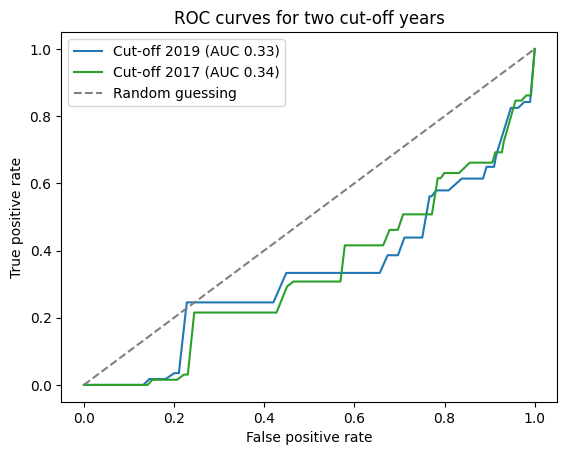

In [22]:
from sklearn.metrics import roc_curve

def roc_for_cutoff(cutoff):
    d = df.sort_values("DATE").copy()
    d["WEEK"] = d["DATE"].dt.to_period("W").dt.start_time
    weekly = d.groupby("WEEK").size()
    weekly = weekly.reindex(pd.date_range(weekly.index.min(), weekly.index.max(), freq="W-MON"), fill_value=0)
    d["PREV_WEEK_COUNT"] = d["WEEK"].map(weekly.shift(1).fillna(0)).fillna(0)

    tr = d[d["DATE"].dt.year <= cutoff]
    te = d[d["DATE"].dt.year > cutoff]
    m = LogisticRegression(class_weight="balanced", max_iter=1000)
    m.fit(tr[["PREV_WEEK_COUNT"]], tr["SEVERE"])
    p = m.predict_proba(te[["PREV_WEEK_COUNT"]])[:, 1]
    fpr, tpr, _ = roc_curve(te["SEVERE"], p)
    return fpr, tpr, roc_auc_score(te["SEVERE"], p)

fig, ax = plt.subplots()
for cutoff, colour in [(2019, "tab:blue"), (2017, "tab:green")]:
    fpr, tpr, auc = roc_for_cutoff(cutoff)
    ax.plot(fpr, tpr, color=colour, label=f"Cut-off {cutoff} (AUC {auc:.2f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guessing")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves for two cut-off years")
ax.legend()
fig.savefig("roc_cutoff_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Log the feature tests to MLflow

In [24]:
!pip install mlflow -q
import mlflow

mlflow.set_experiment("flood-warnings-classifier")

runs = [
    {"feature": "area_month_logreg", "cutoff": 2019, "auc": None, "severe_f1": 0.0},
    {"feature": "area_history_rate", "cutoff": 2019, "auc": 0.451, "severe_f1": 0.0},
    {"feature": "weekly_warning_count", "cutoff": 2019, "auc": 0.334, "severe_f1": 0.002},
]

for r in runs:
    with mlflow.start_run(run_name=f"{r['feature']}_cutoff{r['cutoff']}"):
        mlflow.log_params({
            "feature": r["feature"],
            "cutoff": r["cutoff"],
            "target": "severe_vs_other",
            "class_weight": "balanced",
            "threshold": 0.5,
        })
        metrics = {"severe_f1": r["severe_f1"]}
        if r["auc"] is not None:
            metrics["auc"] = r["auc"]
        mlflow.log_metrics(metrics)

print("Logged", len(runs), "feature runs to MLflow")

2026/11/05 22:18:29 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/05 22:18:29 INFO mlflow.store.db.utils: Updating database tables
2026/11/05 22:18:32 INFO mlflow.tracking.fluent: Experiment with name 'flood-warnings-classifier' does not exist. Creating a new experiment.


Logged 3 feature runs to MLflow


## 13. Build a weekly area grid with a 30-day severe label

In [25]:
import numpy as np

# Keep the most common areas so the grid stays small enough for Colab
top_areas = df["AREA"].value_counts().head(10).index
d = df[df["AREA"].isin(top_areas)].copy()

# One row per area per week, across the whole period
d["WEEK"] = d["DATE"].dt.to_period("W").dt.start_time
weeks = pd.date_range(d["WEEK"].min(), d["WEEK"].max(), freq="W-MON")
grid = pd.MultiIndex.from_product([top_areas, weeks], names=["AREA", "WEEK"]).to_frame(index=False)

# Count severe warnings per area per week
severe_weekly = (
    d[d["SEVERE"] == 1].groupby(["AREA", "WEEK"]).size().rename("severe_count").reset_index()
)
grid = grid.merge(severe_weekly, on=["AREA", "WEEK"], how="left").fillna({"severe_count": 0})

# Label: a severe warning in this area in the next 30 days (about 4 weeks, this week excluded)
grid = grid.sort_values(["AREA", "WEEK"]).reset_index(drop=True)
grid["SEVERE_NEXT_4W"] = (
    grid.groupby("AREA")["severe_count"]
    .transform(lambda s: s[::-1].rolling(4, min_periods=1).sum()[::-1].shift(-1).fillna(0))
    .gt(0)
    .astype(int)
)

print("grid rows:", len(grid))
print("positive labels:", grid["SEVERE_NEXT_4W"].sum())
print(grid.head())

grid rows: 10630
positive labels: 56
                                       AREA       WEEK  severe_count  \
0  East Anglia - Essex, Norfolk and Suffolk 2006-02-13           0.0   
1  East Anglia - Essex, Norfolk and Suffolk 2006-02-20           0.0   
2  East Anglia - Essex, Norfolk and Suffolk 2006-02-27           0.0   
3  East Anglia - Essex, Norfolk and Suffolk 2006-03-06           0.0   
4  East Anglia - Essex, Norfolk and Suffolk 2006-03-13           0.0   

   SEVERE_NEXT_4W  
0               0  
1               0  
2               0  
3               0  
4               0  


## 14. Add past-only features to the grid

In [26]:
grid["severe_count"] = grid["severe_count"].astype(int)

# Warnings and updates per area-week, using only what was known in that week
all_weekly = (
    d.assign(IS_UPDATE=d["TYPE_CLEAN"].str.startswith("update"))
)
counts = all_weekly.groupby(["AREA", "WEEK"]).agg(
    warnings_week=("DATE", "size"),
).reset_index()
grid = grid.merge(counts, on=["AREA", "WEEK"], how="left").fillna({"warnings_week": 0})

# Past-only rolling features: the previous 4 weeks, excluding the current week
grid = grid.sort_values(["AREA", "WEEK"]).reset_index(drop=True)
grid["warnings_past_4w"] = (
    grid.groupby("AREA")["warnings_week"].transform(lambda s: s.shift(1).rolling(4, min_periods=1).sum()).fillna(0)
)
grid["severe_past_12w"] = (
    grid.groupby("AREA")["severe_count"].transform(lambda s: s.shift(1).rolling(12, min_periods=1).sum()).fillna(0)
)

print(grid[["warnings_past_4w", "severe_past_12w"]].describe())

       warnings_past_4w  severe_past_12w
count      10630.000000     10630.000000
mean          10.005268         0.065475
std           24.015028         0.722111
min            0.000000         0.000000
25%            0.000000         0.000000
50%            0.000000         0.000000
75%            7.000000         0.000000
max          226.000000        13.000000


## 15. Split the grid by week and check the test positives

In [27]:
grid["YEAR"] = grid["WEEK"].dt.year
g_train = grid[grid["YEAR"] <= CUTOFF]
g_test = grid[grid["YEAR"] > CUTOFF]

print("train rows:", len(g_train), "positives:", g_train["SEVERE_NEXT_4W"].sum())
print("test rows:", len(g_test), "positives:", g_test["SEVERE_NEXT_4W"].sum())

train rows: 7250 positives: 25
test rows: 3380 positives: 31


## 16. Train on the 30-day label and log the results to MLflow

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score

features = ["warnings_past_4w", "severe_past_12w"]

model_30 = LogisticRegression(class_weight="balanced", max_iter=1000)
model_30.fit(g_train[features], g_train["SEVERE_NEXT_4W"])
probs_30 = model_30.predict_proba(g_test[features])[:, 1]
pred_30 = (probs_30 >= 0.5).astype(int)

y_test_30 = g_test["SEVERE_NEXT_4W"]
baseline_30 = [0] * len(y_test_30)

auc_30 = roc_auc_score(y_test_30, probs_30)
f1_model_30 = f1_score(y_test_30, pred_30, zero_division=0)
f1_base_30 = f1_score(y_test_30, baseline_30, zero_division=0)

print("baseline F1:", round(f1_base_30, 3))
print("model AUC:", round(auc_30, 3))
print("model severe F1:", round(f1_model_30, 3))

mlflow.set_experiment("flood-warnings-classifier")
with mlflow.start_run(run_name="30day_warning_count_logreg"):
    mlflow.log_params({
        "target": "severe_next_4_weeks",
        "features": ",".join(features),
        "cutoff": CUTOFF,
        "class_weight": "balanced",
        "threshold": 0.5,
        "top_areas": len(top_areas),
    })
    mlflow.log_metrics({
        "auc": auc_30,
        "severe_f1": f1_model_30,
        "baseline_f1": f1_base_30,
        "test_positives": int(y_test_30.sum()),
    })

baseline F1: 0.0
model AUC: 0.729
model severe F1: 0.043


## 17. Choose the threshold on the training years

In [29]:
from sklearn.metrics import precision_recall_curve

probs_train = model_30.predict_proba(g_train[features])[:, 1]
y_train_30 = g_train["SEVERE_NEXT_4W"]

precision, recall, thresholds = precision_recall_curve(y_train_30, probs_train)
f1_curve = 2 * precision * recall / (precision + recall + 1e-9)

best = f1_curve[:-1].argmax()
best_threshold = thresholds[best]
print("best training threshold:", round(best_threshold, 3))
print("training F1 at that threshold:", round(f1_curve[best], 3))

pred_tuned = (probs_30 >= best_threshold).astype(int)
f1_tuned = f1_score(y_test_30, pred_tuned, zero_division=0)
print("test F1 with training threshold:", round(f1_tuned, 3))

best training threshold: 0.978
training F1 at that threshold: 0.321
test F1 with training threshold: 0.0


## 18. Test the 30-day model at a second cut-off

In [30]:
def run_30day(cutoff):
    tr = grid[grid["YEAR"] <= cutoff]
    te = grid[grid["YEAR"] > cutoff]
    m = LogisticRegression(class_weight="balanced", max_iter=1000)
    m.fit(tr[features], tr["SEVERE_NEXT_4W"])
    p = m.predict_proba(te[features])[:, 1]
    pred = (p >= 0.5).astype(int)
    return {
        "cutoff": cutoff,
        "train_positives": int(tr["SEVERE_NEXT_4W"].sum()),
        "test_positives": int(te["SEVERE_NEXT_4W"].sum()),
        "AUC": round(roc_auc_score(te["SEVERE_NEXT_4W"], p), 3),
        "severe_F1": round(f1_score(te["SEVERE_NEXT_4W"], pred, zero_division=0), 3),
    }

results_30 = pd.DataFrame([run_30day(c) for c in [2017, 2018, 2019, 2020]])
print(results_30.to_string(index=False))

 cutoff  train_positives  test_positives   AUC  severe_F1
   2017               25              31 0.733      0.031
   2018               25              31 0.728      0.037
   2019               25              31 0.729      0.043
   2020               39              17 0.711      0.023


## 19. Extend the grid to all areas with enough warnings

In [31]:
area_totals = df["AREA"].value_counts()
ext_areas = area_totals[area_totals >= 50].index
print("areas kept:", len(ext_areas), "of", df["AREA"].nunique())

d_ext = df[df["AREA"].isin(ext_areas)].copy()
d_ext["WEEK"] = d_ext["DATE"].dt.to_period("W").dt.start_time
weeks_ext = pd.date_range(d_ext["WEEK"].min(), d_ext["WEEK"].max(), freq="W-MON")
grid_ext = pd.MultiIndex.from_product([ext_areas, weeks_ext], names=["AREA", "WEEK"]).to_frame(index=False)

sev_ext = (
    d_ext[d_ext["SEVERE"] == 1].groupby(["AREA", "WEEK"]).size().rename("severe_count").reset_index()
)
grid_ext = grid_ext.merge(sev_ext, on=["AREA", "WEEK"], how="left").fillna({"severe_count": 0})
grid_ext["severe_count"] = grid_ext["severe_count"].astype(int)

warn_ext = d_ext.groupby(["AREA", "WEEK"]).size().rename("warnings_week").reset_index()
grid_ext = grid_ext.merge(warn_ext, on=["AREA", "WEEK"], how="left").fillna({"warnings_week": 0})

grid_ext = grid_ext.sort_values(["AREA", "WEEK"]).reset_index(drop=True)
grid_ext["SEVERE_NEXT_4W"] = (
    grid_ext.groupby("AREA")["severe_count"]
    .transform(lambda s: s[::-1].rolling(4, min_periods=1).sum()[::-1].shift(-1).fillna(0))
    .gt(0)
    .astype(int)
)
grid_ext["warnings_past_4w"] = grid_ext.groupby("AREA")["warnings_week"].transform(
    lambda s: s.shift(1).rolling(4, min_periods=1).sum()
).fillna(0)
grid_ext["severe_past_12w"] = grid_ext.groupby("AREA")["severe_count"].transform(
    lambda s: s.shift(1).rolling(12, min_periods=1).sum()
).fillna(0)
grid_ext["YEAR"] = grid_ext["WEEK"].dt.year

print("grid rows:", len(grid_ext), "positives:", grid_ext["SEVERE_NEXT_4W"].sum())

areas kept: 54 of 59
grid rows: 57402 positives: 382


## 20. Refit the 30-day model on the extended grid

In [32]:
g_train_ext = grid_ext[grid_ext["YEAR"] <= CUTOFF]
g_test_ext = grid_ext[grid_ext["YEAR"] > CUTOFF]

print("train positives:", g_train_ext["SEVERE_NEXT_4W"].sum(),
      "| test positives:", g_test_ext["SEVERE_NEXT_4W"].sum())

m_ext = LogisticRegression(class_weight="balanced", max_iter=1000)
m_ext.fit(g_train_ext[features], g_train_ext["SEVERE_NEXT_4W"])
p_ext = m_ext.predict_proba(g_test_ext[features])[:, 1]
pred_ext = (p_ext >= 0.5).astype(int)

y_ext = g_test_ext["SEVERE_NEXT_4W"]
print("extended AUC:", round(roc_auc_score(y_ext, p_ext), 3))
print("extended severe F1 (threshold 0.5):", round(f1_score(y_ext, pred_ext, zero_division=0), 3))
print("baseline F1:", round(f1_score(y_ext, [0] * len(y_ext), zero_division=0), 3))

train positives: 307 | test positives: 75
extended AUC: 0.823
extended severe F1 (threshold 0.5): 0.031
baseline F1: 0.0
